In [1]:
from biASE import General_Bias_Calculator

In [2]:
from ase.atoms import Atoms



import numpy as np
import matplotlib.pyplot as plt
from ase.calculators.calculator import Calculator, all_changes

from ase.geometry import find_mic
import jax.numpy as jnp
from jax import jit
from jax import grad ,jacfwd,jacrev

In [3]:
import numpy as np
from ase.geometry import find_mic




def compute_cv(atoms_pos):
    p1 = atoms_pos[0]
    p2 = atoms_pos[1]
    p3 = atoms_pos[2]
    #print(p1,p2,p3)
    # Get distance vectors and distances
    displace = p2 - p1 #find_mic(p2 - p1, atoms.cell, atoms.pbc)
    bondlength = jnp.linalg.norm(displace)
    d_p3_p1 = p3 - p1 #find_mic(p3 - p1, atoms.cell, atoms.pbc)
    norm_p3_p1 = jnp.linalg.norm(d_p3_p1)

    # Get angle with z axis
    z_axis = jnp.array([0, 0, 1])
    theta = jnp.arccos(jnp.dot(z_axis, d_p3_p1)/(jnp.linalg.norm(z_axis)*norm_p3_p1))
    #print(index)
    return jnp.array([bondlength,theta])


In [4]:
atoms = Atoms('H3',[[1.0,0.0,0.0],[2.0,0.0,0.0],[2.5,1.0,0.0]])
pos = atoms.get_positions()
print(pos)
print(compute_cv(pos))
deriv_cv = jit(jacfwd(compute_cv)) #get the derivative of the cvs
print(deriv_cv(pos))

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


[[1.  0.  0. ]
 [2.  0.  0. ]
 [2.5 1.  0. ]]
[1.        1.5707964]
[[[-1.         0.         0.       ]
  [ 1.         0.         0.       ]
  [ 0.         0.         0.       ]]

 [[-0.        -0.         0.5547002]
  [-0.        -0.        -0.       ]
  [-0.        -0.        -0.5547002]]]


In [5]:
### Numerical check of the derivative of the distance

h=0.0001
d_cv = []

for j in range(3):
    for i in range(3):
        pos = atoms.get_positions()
        pos[j][i]-=h
        atoms.set_positions(pos)
        e_m = compute_cv(pos)[0]
        #print(e_m)
        pos[j][i]+=2*h
        atoms.set_positions(pos)
        e_p= compute_cv(pos)[0]
        #print(e_p)
        d_cv.append(float((e_p-e_m)/(2*h)))
        pos[0][i]-=h
        atoms.set_positions(pos)

print(np.array(d_cv).reshape(3,3))

[[-1.00016594  0.          0.        ]
 [ 1.00016594  0.          0.        ]
 [ 0.          0.          0.        ]]


In [7]:
### Numerical check of the derivative of theta

h=0.0001
d_cv = []

for j in range(3):
    for i in range(3):
        pos = atoms.get_positions()
        pos[j][i]-=h
        atoms.set_positions(pos)
        e_m = compute_cv(pos)[1]
        #print(e_m)
        pos[j][i]+=2*h
        atoms.set_positions(pos)
        e_p= compute_cv(pos)[1]
        #print(e_p)
        d_cv.append(float((e_p-e_m)/(2*h)))
        pos[0][i]-=h
        atoms.set_positions(pos)

print(np.array(d_cv).reshape(3,3))

[[ 0.          0.          0.55551529]
 [ 0.          0.          0.        ]
 [ 0.          0.00059605 -0.55551529]]


# PBCS make some problems

In [6]:
def potential_energy(x, y, deltax, deltay, param1, param2):
    x_wrapped = jnp.mod(x, deltax)
    y_wrapped = jnp.mod(y, deltay)
    distance_squared = (x_wrapped - param1)**2 + (y_wrapped - param2)**2
    energy = jnp.exp(-distance_squared)
    return jnp.sum(energy)


x = jnp.array([1.0, 2.0, 3.0])
y = jnp.array([0.5, 1.5, 2.5])
box_size_x = 10.0
box_size_y = 5.0

jacobian = jacfwd(potential_energy)(x, y, box_size_x, box_size_y, x, y)
print("Jacobian:", jacobian)

gradient = grad(potential_energy)(x, y, box_size_x, box_size_y,  x, y)
print("Gradient:", gradient)


Jacobian: [0. 0. 0.]
Gradient: [0. 0. 0.]


In [8]:
import numpy as np

def umbrella_potential(x, x0, k, delta):
    """
    Generate an umbrella sampling bias potential for a single collective variable using a harmonic biasing potential.

    Parameters:
        x (float): The value of the collective variable.
        x0 (float): The center of the bias potential.
        k (float): The spring constant of the bias potential.
        delta (float): The spacing between the umbrella windows.

    Returns:
        float: The bias potential at the given collective variable value.
    """
    dx = np.mod(x - x0, delta) - delta / 2.0
    return 0.5 * k * dx**2


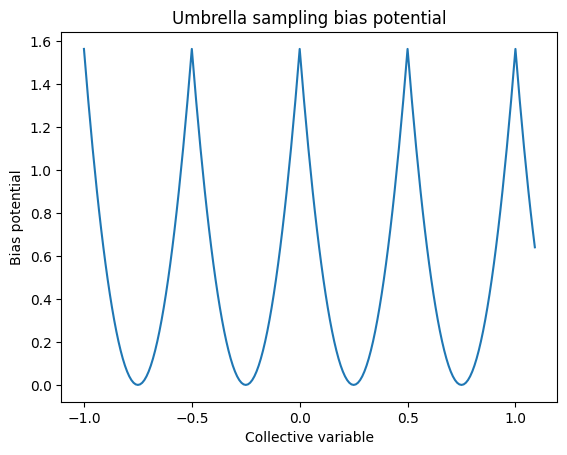

In [9]:
import matplotlib.pyplot as plt

# Define the parameters for the umbrella potential
x0 = 0.0  # Center of the bias potential
k = 50.0  # Spring constant of the bias potential
delta = 0.5 # Spacing between the umbrella windows

# Generate the bias potential values for a range of collective variable values
x_range = np.arange(-1.0, 1.1, 0.01)
bias_potential = [umbrella_potential(x, x0, k, delta) for x in x_range]

# Plot the umbrella sampling bias potential
fig, ax = plt.subplots()
ax.plot(x_range, bias_potential)
ax.set_xlabel('Collective variable')
ax.set_ylabel('Bias potential')
ax.set_title('Umbrella sampling bias potential')
plt.show()


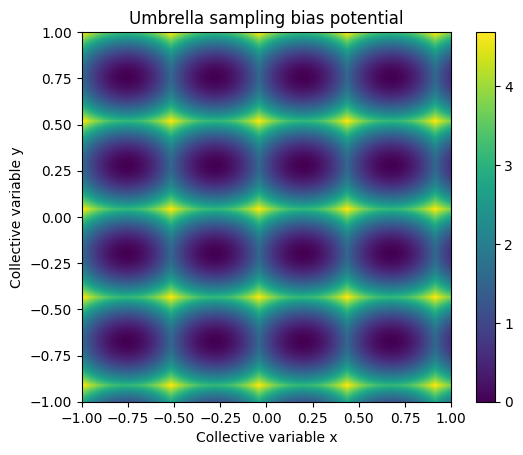

In [10]:
def umbrella_potential(x, y, x0, y0, kx, ky, deltax, deltay):
    dx = np.mod(x - x0, deltax) - deltax / 2.0
    dy = np.mod(y - y0, deltay) - deltay / 2.0
    return 0.5 * kx * dx**2 + 0.5 * ky * dy**2

# Define the parameters for the umbrella potential
x0 = 0.0  # Center of the bias potential in x dimension
y0 = 0.0  # Center of the bias potential in y dimension
kx = 50.0  # Spring constant of the bias potential in x dimension
ky = 100.0  # Spring constant of the bias potential in y dimension
deltax = 0.5  # Spacing between the umbrella windows in x dimension
deltay = 0.5  # Spacing between the umbrella windows in y dimension

# Generate the bias potential values for a grid of collective variable values
x_range = np.arange(-1.0, 1.1, 0.01)
y_range = np.arange(-1.0, 1.1, 0.01)
X, Y = np.meshgrid(x_range, y_range)
bias_potential = umbrella_potential(X, Y, x0, y0, kx, ky, deltax, deltay)

# Plot the 2D umbrella sampling bias potential
fig, ax = plt.subplots()
im = ax.imshow(bias_potential, extent=[-1.0, 1.0, -1.0, 1.0])
ax.set_xlabel('Collective variable x')
ax.set_ylabel('Collective variable y')
ax.set_title('Umbrella sampling bias potential')
plt.colorbar(im)
plt.show()


In [11]:
import numpy as np
from ase.geometry import find_mic
from angle_z_axis import get_z_axis_angle_derv

class ColVar:
    """Base class for collective variables.

    A colvar object must be able to return the value of the collective
    variable through get_colvar() and its gradient via get_colvar_grad.
    To avoid repeated calculations the base class provides a mechanism
    to check if these properties have been evaluated before."""

    def __init__(self):
        self.atoms = None #copy of atoms object from last calculation
        self.cv_value = None
        self.cv_grad = None
        self.counter = 0##

    def get_colvar(self, atoms):
        self.update_colvar(atoms)
        return self.cv_value

    def get_colvar_grad(self, atoms):
        self.update_colvar(atoms)
        return self.cv_grad

    def update_colvar(self, atoms): #, tol=1e-15):
        """check if properties have already been calculated."""

        if self.atoms is None or self.atoms != atoms: #check positions only? (cf. calculator.py)
            self.counter+=1##
            # print('CV computation', self.counter) ##)
            self.compute_cv(atoms)

    def compute_cv(self, atoms):
        """This needs to be implemented in the individual colvar classes.
        Both self.cv_value and self.cv_grad, as well as self.atoms need to be updated."""

        self.atoms = atoms.copy()
       #raise RuntimeError('ColVar class not properly implemented.')


class Dist(ColVar):

    def __init__(self, pair):
        """Distance between two atoms
        pair: list of two atom indices [i0, i1]
        """
        ColVar.__init__(self)
        assert len(pair)==2, "pair has been a list with two atom indices."
        self.pair = pair

    def compute_cv(self, atoms):
        self.atoms = atoms.copy()
        positions = self.atoms.positions
        p1 = positions[self.trip[0]]
        p2 = positions[self.trip[1]]
        p3 = positions[self.trip[2]]

        self.cv_grad = np.zeros_like(positions)

        r_12 = atoms.get_distance(self.pair[0], self.pair[1], mic=True, vector=True)
        dist = atoms.get_distance(self.pair[0], self.pair[1], mic=True)

        self.cv_value = dist
        grad1 = r_12 / dist
        self.cv_grad[self.pair[0]] += grad1
        self.cv_grad[self.pair[1]] -= grad1


class DistDiff(ColVar):

    def __init__(self, triplett):
        """Distance between two atoms
        triplett: list of three atom indices [i0, i1, i2]
        """
        ColVar.__init__(self)
        assert len(triplett)==3, "triplett has been a list with three atom indices."
        self.triplett = triplett

    def compute_cv(self, atoms):
        self.atoms = atoms.copy()
        positions = self.atoms.positions
        self.cv_grad = np.zeros_like(positions)

        p1, p2, p3 = positions[self.triplett]
        # Define distance_1
        displace_1, _ = find_mic(p1 - p2, self.atoms.cell, self.atoms.pbc)
        distance_1 = np.linalg.norm(displace_1)
        # Define distance_2
        displace_2, _ = find_mic(p3 - p1, atoms.cell, atoms.pbc)
        distance_2 = np.linalg.norm(displace_2)
        # Define difference between both distances as new CV
        distance = distance_2 - distance_1

        grad_2 = displace_1 / np.linalg.norm(displace_1)
        grad_3 = displace_2 / np.linalg.norm(displace_2)
        grad_1 = grad_3 + grad_2

        self.cv_value = distance
        self.cv_grad[self.triplett[0]] -= grad_1
        self.cv_grad[self.triplett[1]] += grad_2
        self.cv_grad[self.triplett[2]] += grad_3


class LinearComb(ColVar):

    def __init__(self, trip, lc=[1, 1]):
        """Distance between two atoms
        pair: list of two atom indices [i0, i1]
        lc: linear combination
        """

        ColVar.__init__(self)
        assert len(trip)==3, "trip has been a list with three atom indices."
        self.trip = trip
        self.lc = lc

    def compute_cv(self, atoms):
        self.atoms = atoms.copy()
        positions = self.atoms.positions
        p1 = positions[self.trip[0]]
        p2 = positions[self.trip[1]]
        p3 = positions[self.trip[2]]

        self.cv_grad = np.zeros_like(positions)


        # Get distance vectors and distances
        displace, _ = find_mic(p2 - p1, atoms.cell, atoms.pbc)
        if (displace == p2-p1).all:
            print("No mic needed for p2-p1!")
        bondlength = np.linalg.norm(displace)

        d_p3_p1, _ = find_mic(p3 - p1, atoms.cell, atoms.pbc)
        if (d_p3_p1 == p2-p1).all:
            print("No mic needed for p3-p1!")
        norm_p3_p1 = np.linalg.norm(d_p3_p1)

        # Get angle with z axis
        z_axis = np.array([0, 0, 1])
        theta = np.arccos(np.dot(z_axis, d_p3_p1)/(np.linalg.norm(z_axis)*norm_p3_p1))

        # magnitude = self.spring * (bondlength - self.threshold)
        direction = displace / np.linalg.norm(displace)

        angle_derv = get_z_axis_angle_derv(p1, p3, const=self.lc[1])

        self.cv_value = self.lc[0] * bondlength + self.lc[1] * theta
        self.cv_grad[self.trip[0]] = angle_derv[0] - self.lc[0] * direction
        self.cv_grad[self.trip[1]] = self.lc[0] * direction
        self.cv_grad[self.trip[2]] = angle_derv[1]

In [12]:
class ColVar_jnp:
    """Base class for collective variables.

    A ColVar_jnp object must be able to return the value of the collective
    variable through get_ColVar_jnp() and its gradient via get_ColVar_jnp_grad.
    To avoid repeated calculations the base class provides a mechanism
    to check if these properties have been evaluated before."""

    def __init__(self):
        self.positions = None #copy of atoms object from last calculation
        self.cv_value = None
        self.cv_grad = None
        self.counter = 0##

    def get_colvar(self, positions):
        self.update_colvar(positions)
        return self.cv_value

    def get_colvar_grad(self, positions):
        grad_cv = grad(self.get_colvar)
        self.cv_grad=grad_cv(positions)
        return self.cv_grad

    def update_colvar(self, positions): #, tol=1e-15):
        """check if properties have already been calculated."""

        if self.positions is None or self.positions != positions: #check positions only? (cf. calculator.py)
            self.counter+=1##
            # print('CV computation', self.counter) ##)
            self.compute_cv(positions)

    def compute_cv(self, positions):
        """This needs to be implemented in the individual ColVar_jnp classes.
        Both self.cv_value and self.cv_grad, as well as self.atoms need to be updated."""

        self.positions = positions.copy()
       #raise RuntimeError('ColVar_jnp class not properly implemented.')


class Dist_jnp(ColVar_jnp):

    def __init__(self, pair):
        """Distance between two atoms
        pair: list of two atom indices [i0, i1]
        """
        ColVar_jnp.__init__(self)
        assert len(pair)==2, "pair has been a list with two atom indices."
        self.pair = pair

    def compute_cv(self, positions):
        self.cv_grad = jnp.zeros_like(positions)
        #dist = atoms.get_distance(self.pair[0], self.pair[1], mic=True)
        dist = positions[self.pair[0]] - positions[self.pair[1]]
        self.cv_value = dist



class DistDiff_jnp(ColVar_jnp):

    def __init__(self, triplett):
        """Distance between two atoms
        triplett: list of three atom indices [i0, i1, i2]
        """
        ColVar_jnp.__init__(self)
        assert len(triplett)==3, "triplett has been a list with three atom indices."
        self.triplett = triplett

    def compute_cv(self, positions):
        self.cv_grad = jnp.zeros_like(positions)

        p1, p2, p3 = positions[self.triplett]
        # Define distance_1
        #displace_1, _ = find_mic(p1 - p2, self.atoms.cell, self.atoms.pbc)
        distance_1 = jnp.linalg.norm(p1-  p2)
        # Define distance_2
        #displace_2, _ = find_mic(p3 - p1, atoms.cell, atoms.pbc)
        distance_2 = jnp.linalg.norm(p3 - p1)
        # Define difference between both distances as new CV
        distance = distance_2 - distance_1

        self.cv_value = distance
        

class LinearComb_jnp(ColVar_jnp):

    def __init__(self, trip, lc=[1, 1]):
        """Distance between two atoms
        pair: list of two atom indices [i0, i1]
        lc: linear combination
        """

        ColVar_jnp.__init__(self)
        assert len(trip)==3, "trip has been a list with three atom indices."
        self.trip = trip
        self.lc = lc

    def compute_cv(self, positions):
        p1 = positions[self.trip[0]]
        p2 = positions[self.trip[1]]
        p3 = positions[self.trip[2]]

        self.cv_grad = jnp.zeros_like(positions)


        # Get distance vectors and distances
        '''displace, _ = find_mic(p2 - p1, atoms.cell, atoms.pbc)
        if (displace == p2-p1).all:
            print("No mic needed for p2-p1!")'''
        bondlength = jnp.linalg.norm(p2 - p1)

        '''d_p3_p1, _ = find_mic(p3 - p1, atoms.cell, atoms.pbc)
        if (d_p3_p1 == p2-p1).all:
            print("No mic needed for p3-p1!")'''
        d_p3_p1 = p3 - p1
        norm_p3_p1 = jnp.linalg.norm(d_p3_p1)

        # Get angle with z axis
        z_axis = jnp.array([0, 0, 1])
        theta = jnp.arccos(jnp.dot(z_axis, d_p3_p1)/(jnp.linalg.norm(z_axis)*norm_p3_p1))

        self.cv_value = self.lc[0] * bondlength + self.lc[1] * theta


In [13]:
from ase.build import molecule

water = molecule("H2O")
two_cv = LinearComb(trip=[0,1,2])
cvs = two_cv.get_colvar(water)
dcvs = two_cv.get_colvar_grad(water)
print(cvs,dcvs)

No mic needed for p2-p1!
No mic needed for p3-p1!
3.20258755078489 [[ 0.         -1.42365387  1.42924745]
 [ 0.          0.78801008 -0.61566233]
 [ 0.          0.63564379 -0.81358512]]


In [14]:
two_cv_jnp = LinearComb_jnp(trip=[0,1,2])
cvs_jnp = two_cv_jnp.get_colvar(water.positions)
dcvs_jnp = two_cv_jnp.get_colvar_grad(water.positions)
print(cvs_jnp,dcvs_jnp)

3.2025876 [[ 0.         -1.4236538   1.4292475 ]
 [ 0.          0.7880101  -0.61566234]
 [ 0.          0.6356438  -0.81358516]]


In [15]:
from mace.calculators import mace_mp
mace_calc = mace_mp(model="medium", dispersion=False, default_dtype="float64",device='cuda:1', )

from ase.build import fcc111, add_adsorbate
from ase import Atoms
from ase.constraints import FixAtoms

# Create a 4x4 Rh(111) slab with 4 layers and 10 Å of vacuum
slab = fcc111('Rh', size=(4, 4, 4), vacuum=10.0)

# Define the HCO molecule
HCO = Atoms('HCO', positions=[(0, 0, 0), (1.1, 0, 0), (1.1, 1.2, 0)])

# Define the adsorption height for HCO above the hollow site (adjust as necessary)
adsorption_height = 1.5  # distance in Angstroms from the slab

# Add HCO to the hollow site of the slab (hollow = position between 3 neighboring atoms)
# You can specify 'hollow' directly to target the hollow site
add_adsorbate(slab, HCO, adsorption_height, position=(5,3))

# Freeze the lowest layer of the slab (z_threshold sets the cutoff for the lowest layer)
z_threshold = min(slab.positions[:, 2]) + 0.1
constraint = FixAtoms(indices=[atom.index for atom in slab if atom.position[2] < z_threshold])
slab.set_constraint(constraint)

# Now the slab is ready for DFT calculation



/work/home/ngoen/jax_env/lib/python3.10/site-packages/e3nn/o3/_wigner.py:10: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  _Jd, _W3j_flat, _W3j_indices = torch.load(os.path.

Using Materials Project MACE for MACECalculator with /home/ngoen/.cache/mace/5yyxdm76
Using float64 for MACECalculator, which is slower but more accurate. Recommended for geometry optimization.


/work/home/ngoen/jax_env/lib/python3.10/site-packages/mace/calculators/mace.py:127: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(f=model_path, map_location=devic

In [16]:
from ase.optimize import BFGS
slab.calc = mace_calc
BFGS(slab,trajectory="test.traj").run(fmax=0.05,steps=150)

      Step     Time          Energy          fmax
BFGS:    0 08:22:13     -466.996840       11.613510
BFGS:    1 08:22:14     -468.814980        4.312097
BFGS:    2 08:22:16     -469.361463        3.427479
BFGS:    3 08:22:18     -469.961574        5.363575
BFGS:    4 08:22:21     -470.281623        1.838912
BFGS:    5 08:22:21     -470.416324        1.812076
BFGS:    6 08:22:21     -470.687991        2.474733
BFGS:    7 08:22:21     -470.767774        1.675355
BFGS:    8 08:22:21     -470.873751        0.854267
BFGS:    9 08:22:21     -470.927805        1.000762
BFGS:   10 08:22:21     -470.998744        1.381109
BFGS:   11 08:22:21     -471.028671        2.028432
BFGS:   12 08:22:21     -471.068421        0.659049
BFGS:   13 08:22:21     -471.099125        0.579341
BFGS:   14 08:22:21     -471.151030        1.195101
BFGS:   15 08:22:21     -471.173513        1.041518
BFGS:   16 08:22:21     -471.196783        0.543462
BFGS:   17 08:22:21     -471.210057        0.336670
BFGS:   18 08:

True

In [17]:
from ase.md.langevin import Langevin
from ase import units
from ase.md.velocitydistribution import MaxwellBoltzmannDistribution

initial = slab.copy()
MaxwellBoltzmannDistribution(slab, temperature_K=300)
dyn = Langevin(slab, timestep=.5 * units.fs, temperature_K=300, friction=0.1, trajectory='HCO_on_Rh.traj',fixcm=False)#Andersen(atoms, timestep=.5 * units.fs, temperature_K=3000, andersen_prob=0.01,trajectory='md.traj')#


N_steps = int(5e2)
dyn.run(N_steps)

True

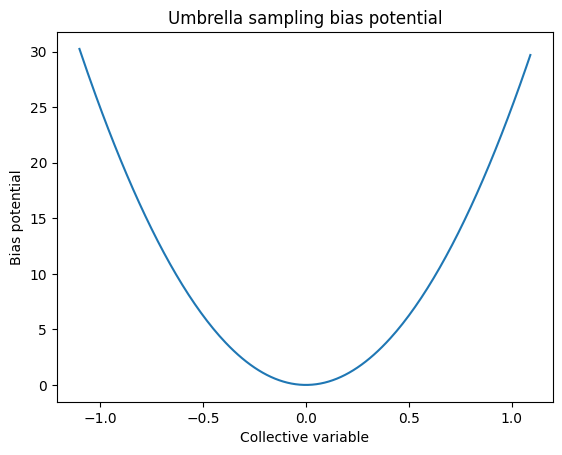

In [18]:
def umbrella_potential(x, x0, k):
    """
    Generate an umbrella sampling bias potential for a single collective variable using a harmonic biasing potential.

    Parameters:
        x (float): The value of the collective variable.
        x0 (float): The center of the bias potential.
        k (float): The spring constant of the bias potential.
        delta (float): The spacing between the umbrella windows.

    Returns:
        float: The bias potential at the given collective variable value.
    """
    dx = x - x0

    return 0.5 * k * dx**2

# Define the parameters for the umbrella potential
x0 = 0.0  # Center of the bias potential
k = 50.0  # Spring constant of the bias potential

# Generate the bias potential values for a range of collective variable values
x_range = np.arange(-1.1, 1.1, 0.01)
bias_potential = [umbrella_potential(x, x0, k) for x in x_range]

# Plot the umbrella sampling bias potential
fig, ax = plt.subplots()
ax.plot(x_range, bias_potential)
ax.set_xlabel('Collective variable')
ax.set_ylabel('Bias potential')
ax.set_title('Umbrella sampling bias potential')
plt.show()


In [19]:
def diff_theta(positions,indices=[65,64,66],factor=[0.7,-0.71]):
    p1 = positions[indices[0]]
    p2 = positions[indices[1]]
    p3 = positions[indices[2]]
    
    # Get distance vectors and distances
    '''displace, _ = find_mic(p2 - p1, atoms.cell, atoms.pbc)
    if (displace == p2-p1).all:
        print("No mic needed for p2-p1!")'''
    bondlength = jnp.linalg.norm(p2 - p1)

    '''d_p3_p1, _ = find_mic(p3 - p1, atoms.cell, atoms.pbc)
    if (d_p3_p1 == p2-p1).all:
        print("No mic needed for p3-p1!")'''
    d_p3_p1 = p3 - p1
    norm_p3_p1 = jnp.linalg.norm(d_p3_p1)

    # Get angle with z axis
    z_axis = jnp.array([0, 0, 1])
    theta = jnp.arccos(jnp.dot(z_axis, d_p3_p1)/(jnp.linalg.norm(z_axis)*norm_p3_p1))
    #print(bondlength,theta)
    cv_value = factor[0] * bondlength + factor[1] * theta
    return cv_value

In [21]:
print(diff_theta(initial.positions))

0.4207313


In [20]:
from ase.calculators.mixing import SumCalculator
from functools import partial

In [21]:
x0=diff_theta(initial.positions)
k=50.0
print(umbrella_potential(1,x0=x0,k=k))
print(grad(partial(umbrella_potential,x0=diff_theta(initial.positions),k=50.0))(1.0))

8.388805
28.963434


In [22]:
g = partial(umbrella_potential,x0=diff_theta(initial.positions),k=50.0)
df_dx=grad(g)
print(df_dx(1.0))


28.963434


In [23]:

umbrella_bias_calc = General_Bias_Calculator(cv_function=diff_theta,bias_function=partial(umbrella_potential,x0=diff_theta(initial.positions),k=50.0))
biased_mace_calc=SumCalculator([mace_calc,umbrella_bias_calc])
initial.calc = biased_mace_calc
print(initial.get_total_energy(),initial.get_forces())


-471.3028142369657 [[ 0.00000000e+00  0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00]
 [ 1.04193295e-02  5.99687699e-03 -2.64047902e-02]
 [-7.94172459e-03  9.87291914e-04 -5.40482319e-03]
 [-9.98585483e-03 -3.56142070e-03 -1.74329214e-02]
 [ 4.8061668

In [26]:
atoms = initial.copy()
atoms.calc = biased_mace_calc
MaxwellBoltzmannDistribution(slab, temperature_K=300)
dyn = Langevin(atoms, timestep=.5 * units.fs, temperature_K=300, friction=0.1, trajectory='HCO_on_Rh_biased.traj',fixcm=False)#Andersen(atoms, timestep=.5 * units.fs, temperature_K=3000, andersen_prob=0.01,trajectory='md.traj')#


N_steps = int(5e3)
dyn.run(N_steps)

True

In [27]:
umbrella_bias_calc = General_Bias_Calculator(cv_function=diff_theta,bias_function=partial(umbrella_potential,x0=diff_theta(initial.positions)+1,k=50.0))
biased_mace_calc=SumCalculator([mace_calc,umbrella_bias_calc])
atoms = initial.copy()
atoms.calc = biased_mace_calc
MaxwellBoltzmannDistribution(slab, temperature_K=300)
dyn = Langevin(atoms, timestep=.5 * units.fs, temperature_K=300, friction=0.1, trajectory='HCO_on_Rh_biased_1.traj',fixcm=False)#Andersen(atoms, timestep=.5 * units.fs, temperature_K=3000, andersen_prob=0.01,trajectory='md.traj')#


N_steps = int(5e3)
dyn.run(N_steps)

True

In [25]:
from ase.io import read
import csv


In [ ]:
with open("cv_energy_biased.csv", 'w') as file:
    writer =csv.writer(file)
    writer.writerow(["CV","Energy"])

In [40]:
for i in range(-20,20):
    umbrella_bias_calc = General_Bias_Calculator(cv_function=diff_theta,bias_function=partial(umbrella_potential,x0=diff_theta(initial.positions)+0.05*i,k=50.0))
    biased_mace_calc=SumCalculator([mace_calc,umbrella_bias_calc])
    atoms = initial.copy()
    atoms.calc = biased_mace_calc
    BFGS(atoms).run(fmax=0.05,steps=200)
    MaxwellBoltzmannDistribution(slab, temperature_K=300)
    dyn = Langevin(atoms, timestep=.5 * units.fs, temperature_K=300, friction=0.1, trajectory=f'HCO_on_Rh_biased_{i}.traj',fixcm=False)#Andersen(atoms, timestep=.5 * units.fs, temperature_K=3000, andersen_prob=0.01,trajectory='md.traj')#


    N_steps = int(5e2)
    dyn.run(N_steps)
    traj = read(f'HCO_on_Rh_biased_{i}.traj@::1')
    cv_list=[]
    energy_list=[]
    for atoms in traj:
        atoms.calc=biased_mace_calc
        energy=atoms.get_total_energy()
        cv= diff_theta(atoms.positions)
        with open("cv_energy_biased.csv", 'a+') as file:
            writer =csv.writer(file)
            writer.writerow([cv,energy])
            
        energy=atoms.get_total_energy()
        cv= diff_theta(atoms.positions)
        cv_list.append(cv)
        energy_list.append(energy)
    with open("mean_cv_energy.csv", 'a+') as file:
        writer =csv.writer(file)
        writer.writerow([np.mean(np.array(cv_list)),np.mean(np.array(energy_list))])

      Step     Time          Energy          fmax
BFGS:    0 09:44:08     -446.302826       62.087855
BFGS:    1 09:44:08     -459.581278       19.933560
BFGS:    2 09:44:08     -464.011438       10.790214
BFGS:    3 09:44:08     -466.833334        5.039680
BFGS:    4 09:44:08     -467.989655        5.800352
BFGS:    5 09:44:08     -468.295864        4.223427
BFGS:    6 09:44:09     -468.468692        1.830699
BFGS:    7 09:44:09     -468.548109        1.398972
BFGS:    8 09:44:09     -468.611854        1.023617
BFGS:    9 09:44:09     -468.637969        0.718863
BFGS:   10 09:44:09     -468.685527        1.615593
BFGS:   11 09:44:09     -468.729005        1.869475
BFGS:   12 09:44:09     -468.805326        1.904911
BFGS:   13 09:44:09     -468.903647        1.310295
BFGS:   14 09:44:09     -469.000429        0.501587
BFGS:   15 09:44:09     -469.071780        2.535906
BFGS:   16 09:44:09     -469.200712        3.631431
BFGS:   17 09:44:09     -469.276897        4.077876
BFGS:   18 09:

In [34]:
with open("cv_energy.csv", 'w') as file:
    writer =csv.writer(file)
    writer.writerow(["CV","Energy"])

In [38]:
for i in range(-10,10):
    traj = read(f'HCO_on_Rh_biased_{i}.traj@::1')
    for atoms in traj:
        atoms.calc=mace_calc
        energy=atoms.get_total_energy()
        cv= diff_theta(atoms.positions)
        with open("cv_energy.csv", 'a+') as file:
            writer =csv.writer(file)
            writer.writerow([cv,energy])
            

KeyboardInterrupt: 

In [39]:
for i in range(-20,20):
    traj = read(f'HCO_on_Rh_biased_{i}.traj@::1')
    cvs=[]
    energies=[]
    for atoms in traj:
        atoms.calc=mace_calc
        energy=atoms.get_total_energy()
        cv= diff_theta(atoms.positions)
        cvs.append(cv)
        energies.append(energy)
    with open("mean_cv_energy.csv", 'a+') as file:
        writer =csv.writer(file)
        writer.writerow([np.mean(np.array(cvs)),np.mean(np.array(energies))])

In [ ]:
for i in range(-10,10):
    umbrella_bias_calc = General_Bias_Calculator(cv_function=diff_theta,bias_function=partial(umbrella_potential,x0=diff_theta(initial.positions)+0.1*i,k=5.0))
    biased_mace_calc=SumCalculator([mace_calc,umbrella_bias_calc])
    atoms = initial.copy()
    atoms.calc = biased_mace_calc
    BFGS(atoms).run(fmax=0.05,steps=200)
    MaxwellBoltzmannDistribution(slab, temperature_K=300)
    dyn = Langevin(atoms, timestep=.5 * units.fs, temperature_K=300, friction=0.1, trajectory=f'HCO_on_Rh_biased_{i}.traj',fixcm=False)#Andersen(atoms, timestep=.5 * units.fs, temperature_K=3000, andersen_prob=0.01,trajectory='md.traj')#


    N_steps = int(5e2)
    dyn.run(N_steps)
    traj = read(f'HCO_on_Rh_biased_{i}.traj@::1')
    for atoms in traj:
        atoms.calc=biased_mace_calc
        energy=atoms.get_total_energy()
        cv= diff_theta(atoms.positions)
        with open("cv_energy_biased.csv", 'a+') as file:
            writer =csv.writer(file)
            writer.writerow([cv,energy])

# We now do it with some more steps which probably takes for ever

In [61]:
for i in range(-20,20):
    umbrella_bias_calc = General_Bias_Calculator(cv_function=diff_theta,bias_function=partial(umbrella_potential,x0=diff_theta(initial.positions)+0.05*i,k=50.0))
    biased_mace_calc=SumCalculator([mace_calc,umbrella_bias_calc])
    atoms = initial.copy()
    atoms.calc = biased_mace_calc
    BFGS(atoms).run(fmax=0.05,steps=200)
    MaxwellBoltzmannDistribution(slab, temperature_K=300)
    dyn = Langevin(atoms, timestep=.5 * units.fs, temperature_K=300, friction=0.1, trajectory=f'HCO_on_Rh_biased_{i}.traj',fixcm=False)#Andersen(atoms, timestep=.5 * units.fs, temperature_K=3000, andersen_prob=0.01,trajectory='md.traj')#


    N_steps = int(5e3)
    dyn.run(N_steps)
    traj = read(f'HCO_on_Rh_biased_{i}.traj@2000::1')
    cv_list=[]
    energy_list=[]
    for atoms in traj:
        atoms.calc=biased_mace_calc
        energy=atoms.get_total_energy()
        cv= diff_theta(atoms.positions)
        with open("cv_energy_biased.csv", 'a+') as file:
            writer =csv.writer(file)
            writer.writerow([cv,energy])
            
        energy=atoms.get_total_energy()
        cv= diff_theta(atoms.positions)
        cv_list.append(cv)
        energy_list.append(energy)
    with open("mean_cv_energy.csv", 'a+') as file:
        writer =csv.writer(file)
        writer.writerow([np.mean(np.array(cv_list)),-50*(np.mean(np.array(cv_list))-(diff_theta(initial.positions)+0.05*i)),np.mean(np.array(energy_list))])
        
    

      Step     Time          Energy          fmax
BFGS:    0 15:10:16     -446.302826       62.087855
BFGS:    1 15:10:16     -459.581278       19.933560
BFGS:    2 15:10:16     -464.011438       10.790214
BFGS:    3 15:10:16     -466.833334        5.039680
BFGS:    4 15:10:16     -467.989655        5.800352
BFGS:    5 15:10:16     -468.295864        4.223427
BFGS:    6 15:10:16     -468.468692        1.830699
BFGS:    7 15:10:16     -468.548109        1.398972
BFGS:    8 15:10:16     -468.611854        1.023617
BFGS:    9 15:10:16     -468.637969        0.718863
BFGS:   10 15:10:16     -468.685527        1.615593
BFGS:   11 15:10:16     -468.729005        1.869475
BFGS:   12 15:10:16     -468.805326        1.904911
BFGS:   13 15:10:16     -468.903647        1.310295
BFGS:   14 15:10:16     -469.000429        0.501587
BFGS:   15 15:10:16     -469.071780        2.535906
BFGS:   16 15:10:16     -469.200712        3.631431
BFGS:   17 15:10:16     -469.276897        4.077876
BFGS:   18 15:

In [29]:
mace_calc_dis = mace_mp(model="medium", dispersion=True, default_dtype="float32",device='cuda:1', )
for i in range(-20,20):
    print(i)
    umbrella_bias_calc = General_Bias_Calculator(cv_function=diff_theta,bias_function=partial(umbrella_potential,x0=diff_theta(initial.positions)+0.05*i,k=50.0))
    biased_mace_calc=SumCalculator([mace_calc_dis,umbrella_bias_calc])
    atoms = initial.copy()
    atoms.calc = biased_mace_calc
    BFGS(atoms).run(fmax=0.05,steps=200)
    MaxwellBoltzmannDistribution(slab, temperature_K=300)
    dyn = Langevin(atoms, timestep=.5 * units.fs, temperature_K=300, friction=0.1, trajectory=f'HCO_on_Rh_dis_biased_{i}_large.traj',fixcm=False)#Andersen(atoms, timestep=.5 * units.fs, temperature_K=3000, andersen_prob=0.01,trajectory='md.traj')#


    N_steps = int(5e4)
    dyn.run(N_steps)
    traj = read(f'HCO_on_Rh_dis_biased_{i}_large.traj@2000::1')
    cv_list=[]
    energy_list=[]
    for atoms in traj:
        atoms.calc=biased_mace_calc
        energy=atoms.get_total_energy()
        cv= diff_theta(atoms.positions)
        with open("largecv_energy_biased_dis.csv", 'a+') as file:
            writer =csv.writer(file)
            writer.writerow([cv,energy])
            
        energy=atoms.get_total_energy()
        cv= diff_theta(atoms.positions)
        cv_list.append(cv)
        energy_list.append(energy)
    with open("large_mean_cv_energy_dis.csv", 'a+') as file:
        writer =csv.writer(file)
        writer.writerow([np.mean(np.array(cv_list)),-50*(np.mean(np.array(cv_list))-(diff_theta(initial.positions)+0.05*i)),np.mean(np.array(energy_list))])
        
    

Using Materials Project MACE for MACECalculator with /home/ngoen/.cache/mace/5yyxdm76
Using float32 for MACECalculator, which is faster but less accurate. Recommended for MD. Use float64 for geometry optimization.
Default dtype float32 does not match model dtype float64, converting models to float32.
Using TorchDFTD3Calculator for D3 dispersion corrections (see https://github.com/pfnet-research/torch-dftd)
-20


/work/home/ngoen/jax_env/lib/python3.10/site-packages/mace/calculators/mace.py:127: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  torch.load(f=model_path, map_location=devic

      Step     Time          Energy          fmax
BFGS:    0 14:23:27     -477.281421       62.066957
BFGS:    1 14:23:27     -490.561548       19.871131
BFGS:    2 14:23:27     -494.985419       10.728132
BFGS:    3 14:23:28     -497.810484        5.085558
BFGS:    4 14:23:28     -499.023518        5.810932
BFGS:    5 14:23:28     -499.358161        4.336687
BFGS:    6 14:23:28     -499.544336        1.856279
BFGS:    7 14:23:29     -499.641465        1.421594
BFGS:    8 14:23:29     -499.716442        1.067866
BFGS:    9 14:23:29     -499.751207        0.731688
BFGS:   10 14:23:29     -499.813445        1.835004
BFGS:   11 14:23:30     -499.863749        2.002831
BFGS:   12 14:23:30     -499.951347        1.885496
BFGS:   13 14:23:30     -500.055273        1.128881
BFGS:   14 14:23:30     -500.130011        0.465990
BFGS:   15 14:23:31     -500.215299        1.690935
BFGS:   16 14:23:31     -500.295707        4.427749
BFGS:   17 14:23:31     -500.425455        1.995202
BFGS:   18 14:

KeyboardInterrupt: 